# MLPA tutorial: MNIST as a three-modality problem

This notebook walks through MLPA end to end on a toy problem:

1. **Data**: every MNIST digit is turned into three *modalities* of different kinds: two sets of image patches
   (continuous feature tokens) and one sequence of discrete token ids. Some modalities are made **missing** at random.
2. **Uni-modal encoders**: one small transformer per modality, pretrained briefly with masked modelling and then
   **frozen**. MLPA itself contains no encoder code; any module with `forward(x, pad, pos) -> (B, T, dim)` works.
3. **Target masks**: which tokens the predictors must predict. We cover the library's strategies, how to pass your own,
   and **how the targets are hidden from the context (cropping vs. replacing) and why that is needed**.
4. **Modality dropout**: `p_any` and the per-modality `p_drop`.
5. **Training MLPA**, with and without modality dropout.
6. **Evaluation**: a linear probe of the digit class on the fused embedding, with modalities removed at test time.
7. **A leak experiment** that shows what goes wrong if the targets are *not* hidden.

The digit labels are used **only** for the evaluation probe. MLPA training is self-supervised.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from torchvision.datasets import MNIST

from mlpa import (MLPA, ModalityConfig, block_mask, bernoulli_mask, crop, random_mask, sample_modality_dropout)

torch.manual_seed(0)
np.random.seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cpu


## 1. Toy multimodal data

From every 28x28 digit we build three modalities:

| modality | kind | tokens | one token is |
|---|---|---|---|
| `top` | continuous features | 8 | a 7x7 patch of the top half (2 rows x 4 columns of patches), 49 pixel values |
| `bottom` | continuous features | 8 | a 7x7 patch of the bottom half |
| `profile` | discrete ids | 28 | the ink in one image column, quantised into 8 levels (id 0..7); id 8 is `[MASK]` |

The modalities overlap in information (the column profile partly describes both halves), as real modalities often do.
Each modality is then made **missing** for 15% of the samples, independently, while every sample keeps at least one.
A missing modality is passed as `present=False` for that row. Its values are ignored and never encoded.

In [2]:
def load(train):
    ds = MNIST('../data', train=train, download=True)
    return ds.data.float() / 255.0, ds.targets


def to_modalities(img):
    n = len(img)
    patches = img.reshape(n, 4, 7, 4, 7).permute(0, 1, 3, 2, 4).reshape(n, 16, 49)   # 4x4 grid of 7x7 patches
    levels = torch.tensor([0.5, 1.5, 3.0, 5.0, 7.0, 9.0, 12.0])
    profile = torch.bucketize(img.sum(1), levels)                                      # (n, 28) ids 0..7
    return {'top': patches[:, :8], 'bottom': patches[:, 8:], 'profile': profile}


def missingness(n, p_missing=0.15, seed=0):
    g = torch.Generator().manual_seed(seed)
    present = torch.rand(n, 3, generator=g) > p_missing
    none = ~present.any(1)
    present[none, torch.randint(0, 3, (int(none.sum()),), generator=g)] = True
    return present


img_tr, y_tr = load(True)
img_te, y_te = load(False)
X_tr, X_te = to_modalities(img_tr), to_modalities(img_te)
P_tr, P_te = missingness(len(img_tr), seed=0), missingness(len(img_te), seed=1)
NAMES = ['top', 'bottom', 'profile']
MASK_ID = 8


def batch(X, P, idx, drop_modalities=()):
    # MLPA input format: {name: {'x': (B, T, ...), 'pad': (B, T) optional, 'present': (B,) optional}}.
    # Leaving a modality out of the dict makes it missing for every sample in the batch.
    return {m: {'x': X[m][idx].to(device), 'present': P[idx, k].to(device)}
            for k, m in enumerate(NAMES) if m not in drop_modalities}


print({m: tuple(v.shape) for m, v in X_tr.items()})
print('fraction present per modality (train):', dict(zip(NAMES, P_tr.float().mean(0).round(decimals=3).tolist())))

{'top': (60000, 8, 49), 'bottom': (60000, 8, 49), 'profile': (60000, 28)}
fraction present per modality (train): {'top': 0.8560000061988831, 'bottom': 0.8479999899864197, 'profile': 0.8510000109672546}


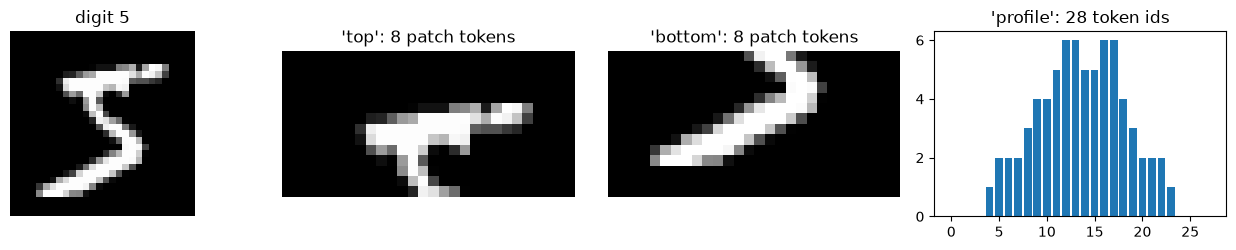

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
i = 0
axes[0].imshow(img_tr[i], cmap='gray'); axes[0].set_title(f'digit {y_tr[i].item()}')
for ax, m in zip(axes[1:3], ['top', 'bottom']):
    p = X_tr[m][i].reshape(2, 4, 7, 7).permute(0, 2, 1, 3).reshape(14, 28)
    ax.imshow(p, cmap='gray'); ax.set_title(f"'{m}': 8 patch tokens")
axes[3].bar(range(28), X_tr['profile'][i]); axes[3].set_title("'profile': 28 token ids")
for ax in axes[:3]:
    ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Uni-modal encoders (pretrained, then frozen)

MLPA works on top of **frozen** uni-modal encoders. The repo has no encoder code. An encoder is any `nn.Module` with

```python
encoder(x, pad, pos) -> (B, T, dim)
#   x   (B, T, ...)  token inputs (ids, feature vectors, ...)
#   pad (B, T) bool  True at padding
#   pos (B, T) long  original position of each token (needed when tokens are cropped, see section 3)
```

Here each encoder is a tiny transformer, pretrained for one epoch with masked modelling. Patches are pretrained by
zeroing 50% of them and reconstructing their pixels. Profile ids are pretrained with MLM: 30% are replaced by
`[MASK]` and their id is predicted. With real data you would use your own pretrained encoders instead.

In [4]:
class Encoder(nn.Module):
    def __init__(self, dim, max_len, vocab=None, in_features=None, layers=2, heads=4):
        super().__init__()
        self.inp = nn.Embedding(vocab, dim) if vocab else nn.Linear(in_features, dim)
        self.pos = nn.Embedding(max_len, dim)
        self.body = nn.TransformerEncoder(nn.TransformerEncoderLayer(dim, heads, 2 * dim, 0.1, 'gelu',
                                                                     batch_first=True, norm_first=True),
                                          layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)

    def forward(self, x, pad, pos):
        return self.norm(self.body(self.inp(x) + self.pos(pos), src_key_padding_mask=pad))


def pretrain(enc, head, x_all, kind, epochs=1, bs=256):
    enc.to(device).train(); head.to(device)
    opt = torch.optim.AdamW(list(enc.parameters()) + list(head.parameters()), lr=1e-3)
    T = x_all.shape[1]
    for _ in range(epochs):
        for idx in torch.randperm(len(x_all)).split(bs):
            x = x_all[idx].to(device)
            pad = torch.zeros(len(x), T, dtype=torch.bool, device=device)
            pos = torch.arange(T, device=device).expand(len(x), T)
            if kind == 'patch':
                m = torch.rand(len(x), T, device=device) < 0.5
                h = enc(x.masked_fill(m[..., None], 0.0), pad, pos)
                loss = F.mse_loss(head(h)[m], x[m])
            else:
                m = torch.rand(len(x), T, device=device) < 0.3
                h = enc(x.masked_fill(m, MASK_ID), pad, pos)
                loss = F.cross_entropy(head(h)[m], x[m])
            opt.zero_grad(); loss.backward(); opt.step()
    print(f'{kind:7s} encoder pretrained, last loss {loss.item():.4f}')
    return enc.eval()


t0 = time.time()
encoders = {
    'top': pretrain(Encoder(64, 8, in_features=49), nn.Linear(64, 49), X_tr['top'], 'patch'),
    'bottom': pretrain(Encoder(64, 8, in_features=49), nn.Linear(64, 49), X_tr['bottom'], 'patch'),
    'profile': pretrain(Encoder(32, 28, vocab=MASK_ID + 1), nn.Linear(32, MASK_ID + 1), X_tr['profile'], 'ids'),
}
print(f'{time.time() - t0:.0f}s')

patch   encoder pretrained, last loss 0.0664
patch   encoder pretrained, last loss 0.0650
ids     encoder pretrained, last loss 0.8316
49s


## 3. Target masks: what the predictors predict

In every training step, MLPA picks some **target** tokens in each present modality. The frozen encoder's output at
those positions, computed on the *unmasked* input, is what the modality's predictor must predict. The remaining
tokens are the **context**. They go through the frozen encoder and the MBT and become the fused summary, which is
the predictor's only input. Per modality you choose:

* `mask_strategy`: `'random'` (exactly `round(mask_ratio * n)` tokens), `'bernoulli'` (each token with
  probability `mask_ratio`, for very short modalities such as a few tabular features) or `'block'` (one contiguous
  span, for sequences where neighbouring tokens are redundant);
* `mask_ratio`: the fraction of tokens that are targets.

At least one target and, if a row has two or more tokens, at least one context token are always kept.
You can also **pass your own masks** with `model(inputs, targets={name: (B, T) bool})`. Below is a custom 2-D block
mask on the patch grid, which suits images better than a 1-D span over the flattened patch order.

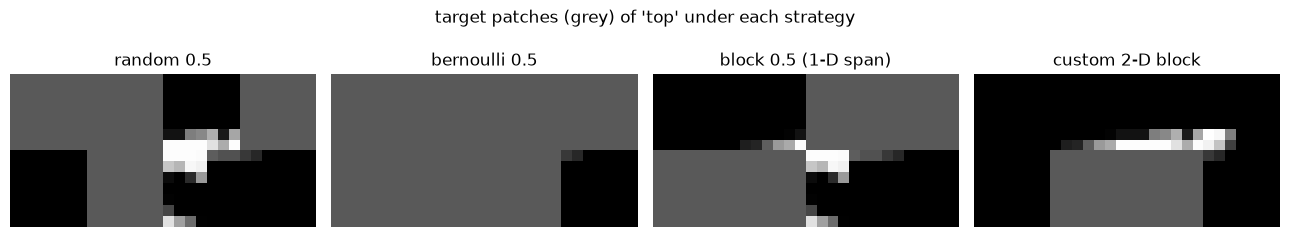

In [5]:
def grid_block_targets(n, rows=2, cols=4, h=1, w=2, generator=None):
    # One h x w block of patches on a rows x cols patch grid, per sample (a custom mask passed via targets=).
    r0 = torch.randint(0, rows - h + 1, (n,), generator=generator)
    c0 = torch.randint(0, cols - w + 1, (n,), generator=generator)
    r, c = torch.arange(rows)[None, :, None], torch.arange(cols)[None, None, :]
    m = (r >= r0[:, None, None]) & (r < (r0 + h)[:, None, None]) & (c >= c0[:, None, None]) & (c < (c0 + w)[:, None, None])
    return m.reshape(n, rows * cols)


g = torch.Generator().manual_seed(3)
valid = torch.ones(4, 8, dtype=torch.bool)
masks = {'random 0.5': random_mask(valid, 0.5, g), 'bernoulli 0.5': bernoulli_mask(valid, 0.5, g),
         'block 0.5 (1-D span)': block_mask(valid, 0.5, g), 'custom 2-D block': grid_block_targets(4, generator=g)}
fig, axes = plt.subplots(1, 4, figsize=(13, 2.4))
top = X_tr['top'][0].reshape(2, 4, 7, 7)
for ax, (name, m) in zip(axes, masks.items()):
    shown = top.clone()
    shown[m[0].reshape(2, 4)] = 0.35                     # grey = target patch
    ax.imshow(shown.permute(0, 2, 1, 3).reshape(14, 28), cmap='gray', vmin=0, vmax=1)
    ax.set_title(name); ax.axis('off')
plt.suptitle("target patches (grey) of 'top' under each strategy", y=1.02); plt.tight_layout(); plt.show()

### Hiding the targets from the context: cropping vs. replacing, and why it is needed

The prediction target at a position is `encoder(x_clean)[pos]`. If the **context** pass of the encoder could still
see the target tokens, their content would flow into the visible tokens' outputs (through attention, convolution,
recurrence, ...), on into the MBT and the fused summary, and the predictor could simply *read the answer back* instead
of inferring it from the other tokens and the other modalities. The loss would drop, but the fused embedding would
learn to compress the inputs rather than to capture the relations between parts and modalities. Leaving
attention-masked or zeroed targets in place is not always enough either: many encoders (convolutions, RNNs,
anything without key-padding masks, or position-dependent normalisation) still let information through. So MLPA hides the
targets **before** the context encoder runs, in one of two ways (`ModalityConfig.context`):

* **`'crop'` (default)**: the target tokens are physically **removed** from the input. The kept tokens are moved to
  the front (in order), the sequence is cut to the longest row, and the original positions are passed as `pos` so the
  encoder still knows *where* each token sits (`mlpa.crop`, as in I-JEPA's context encoder). This works for any
  encoder that takes `pos`. Nothing about the targets can leak, and the encoder runs on fewer tokens, which saves
  compute. Use it for patches, feature vectors, tabular tokens, ...
* **`'replace'`**: your `mask_input(x, target)` replaces the targets in place, e.g. by the `[MASK]` id an MLM-pretrained
  encoder was trained with. The encoder sees a full-length input, the form it was pretrained on, and only the visible
  positions' outputs are passed on to the MBT. Use it when the encoder must see inputs in its pretraining format (BERT-like
  token encoders). Here: `profile`.

Either way, the **target** pass runs on the clean, full input, and only the target positions' outputs are used.
In section 7 we turn the hiding off to show the leak.

In [6]:
x = torch.arange(1, 9).float().reshape(1, 8, 1)            # tokens 1..8 at positions 0..7
target = torch.tensor([[0, 1, 1, 0, 0, 0, 1, 0]]).bool()
x_ctx, pad_ctx, pos_ctx = crop(x, ~target)
print('input tokens     ', x[0, :, 0].int().tolist())
print('targets          ', target[0].int().tolist())
print("'crop'    tokens ", x_ctx[0, :, 0].int().tolist(), ' positions', pos_ctx[0].tolist())
print("'replace' ids    ", X_tr['profile'][0, 8:16].tolist(), '->',
      X_tr['profile'][0, 8:16].masked_fill(target[0], MASK_ID).tolist())

input tokens      [1, 2, 3, 4, 5, 6, 7, 8]
targets           [0, 1, 1, 0, 0, 0, 1, 0]
'crop'    tokens  [1, 4, 5, 6, 8]  positions [0, 3, 4, 5, 7]
'replace' ids     [3, 4, 4, 5, 6, 6, 5, 5] -> [3, 8, 8, 5, 6, 6, 8, 5]


### 3.5 Cropping vs. masking, side by side

Below, one digit goes through both ways of hiding its targets. Each row is one modality:

* **target input**: the clean, full input that the *target* pass of the encoder sees. The targets (red) are only
  marked here, not hidden. Their encoder outputs are what the predictor has to predict.
* **context input, `'crop'`**: what the *context* pass of the encoder receives with cropping. The targets are gone,
  the sequence is shorter, and each kept token carries its original position (`pos`, shown as the label).
* **context input, `'replace'`**: what the context pass receives with replacing. The input keeps its full length, and
  the targets are overwritten in place (zeroed patches for `top`, the `[MASK]` id for `profile`).

In this tutorial `top` and `bottom` use `'crop'` and `profile` uses `'replace'`. Both modes are shown for both kinds of
modality to make the comparison.

In [ ]:
g = torch.Generator().manual_seed(1)
i = 0
top, prof = X_tr['top'][i:i + 1], X_tr['profile'][i:i + 1]                  # (1, 8, 49), (1, 28)
t_top = random_mask(torch.ones(1, 8, dtype=torch.bool), 0.5, g)             # True = target
t_prof = block_mask(torch.ones(1, 28, dtype=torch.bool), 0.4, g)

# 'crop': targets removed, original positions kept in pos.
top_crop, _, pos_top = crop(top, ~t_top)
prof_crop, _, pos_prof = crop(prof, ~t_prof)
# 'replace': full length, targets overwritten in place.
top_repl = top.masked_fill(t_top[..., None], 0.0)
prof_repl = prof.masked_fill(t_prof, MASK_ID)


def patch_grid(ax, tokens, rows, cols, positions, targets=None):
    img = tokens.reshape(rows, cols, 7, 7).permute(0, 2, 1, 3).reshape(rows * 7, cols * 7)
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    for k, p in enumerate(positions):
        r, c = divmod(k, cols)
        ax.add_patch(plt.Rectangle((c * 7 - 0.5, r * 7 - 0.5), 7, 7, fill=False, lw=0.6, ec='tab:blue'))
        if targets is not None and targets[k]:
            ax.add_patch(plt.Rectangle((c * 7 - 0.3, r * 7 - 0.3), 6.6, 6.6, fill=False, lw=2, ec='tab:red'))
        ax.text(c * 7 + 0.3, r * 7 + 1.6, f'pos {p}', color='gold', fontsize=7)
    ax.set_xticks([]); ax.set_yticks([])


def id_bars(ax, ids, positions, targets):
    colors = ['tab:red' if t else 'tab:gray' for t in targets]
    ax.bar(range(len(ids)), ids, color=colors)
    for k, t in enumerate(targets):
        if t:
            ax.axvspan(k - 0.5, k + 0.5, color='tab:red', alpha=0.12, lw=0)   # shade targets (id 0 has no bar)
    ax.set_ylim(0, MASK_ID + 1); ax.axhline(MASK_ID, color='tab:red', ls=':', lw=0.8)
    ax.set_xticks(range(len(ids)), [str(p) for p in positions], fontsize=6, rotation=90)
    ax.set_xlabel('pos')


T_top, T_prof = top.shape[1], prof.shape[1]
fig, axes = plt.subplots(2, 3, figsize=(15, 6), gridspec_kw={'height_ratios': [1, 1.2]})
patch_grid(axes[0, 0], top[0], 2, 4, range(T_top), t_top[0])
patch_grid(axes[0, 1], top_crop[0], 1, top_crop.shape[1], pos_top[0].tolist())
patch_grid(axes[0, 2], top_repl[0], 2, 4, range(T_top), t_top[0])
id_bars(axes[1, 0], prof[0], range(T_prof), t_prof[0])
id_bars(axes[1, 1], prof_crop[0], pos_prof[0].tolist(), [False] * prof_crop.shape[1])
id_bars(axes[1, 2], prof_repl[0], range(T_prof), t_prof[0])

axes[0, 0].set_title(f'target input: clean, {T_top} tokens\n(targets in red)')
axes[0, 1].set_title(f"context input, 'crop': {top_crop.shape[1]} of {T_top} tokens\n(targets removed)")
axes[0, 2].set_title(f"context input, 'replace': {T_top} tokens\n(targets zeroed in place)")
axes[1, 0].set_title(f'target input: clean, {T_prof} ids (targets in red)')
axes[1, 1].set_title(f"context input, 'crop': {prof_crop.shape[1]} of {T_prof} ids")
axes[1, 2].set_title(f"context input, 'replace': {T_prof} ids, targets = [MASK] ({MASK_ID})")
axes[0, 0].set_ylabel("'top' (patches)")
axes[1, 0].set_ylabel("'profile' (token ids)")
plt.tight_layout(); plt.show()

print("encoder input shapes   'top'         'profile'")
print(f'target pass            {tuple(top.shape)!s:13s} {tuple(prof.shape)}')
print(f"context pass, 'crop'   {tuple(top_crop.shape)!s:13s} {tuple(prof_crop.shape)}")
print(f"context pass, 'replace'{tuple(top_repl.shape)!s:13s} {tuple(prof_repl.shape)}")

Both context inputs contain no information about the targets, but they differ in what the encoder sees:

* With **`'crop'`** the encoder gets a shorter sequence (here half the patches), so it runs faster and cannot be
  influenced by the targets at all, whatever its architecture. It has to rely on `pos` to know where each token sits:
  in the cropped `profile` the positions jump over the hidden block.
* With **`'replace'`** the encoder gets an input of the same shape and layout as in pretraining. The hidden positions
  are still there but carry no content (a zero patch or `[MASK]`). Only the outputs at the visible positions are passed on
  to the MBT. This suits encoders pretrained with a mask token, such as the MLM-pretrained `profile` encoder.

In both cases the target pass uses the clean input on the left.

## 4. Modality dropout

Real data has missing modalities, so we want a fused embedding that degrades gracefully when one is absent. Modality
dropout simulates that during training. With probability **`p_any`** (an `MLPA` argument) a sample is selected. Every
present modality `m` of a selected sample is then dropped with its own probability **`p_drop`** (a `ModalityConfig`
argument). The draw is repeated until at least one modality is dropped and at least one stays. Modalities missing in
the data are never dropped, nor are those with `p_drop=0`. Samples with a single present modality are left alone.

A **dropped** modality is different from a **missing** one. A dropped modality's stream is skipped entirely for that
sample, so no gradient reaches the stream, and it is left out of the bottleneck average. Its **predictor still predicts
its targets**, now from the other modalities alone. That is what teaches the model cross-modal prediction. A missing
modality takes part through a learned `[EMPTY]` token and has nothing to predict.

Dropout is only sampled in `model.train()` mode. For a fixed validation draw, pass `drop=` to `forward`.
Because `p_drop` is conditional, the *marginal* drop rate of a modality also depends on `p_any`, on the other modalities
and on missingness. Here it is measured on our data:

In [7]:
P_ANY, P_DROP = 0.7, {'top': 0.4, 'bottom': 0.4, 'profile': 0.2}
drop = sample_modality_dropout(P_tr, P_ANY, torch.tensor([P_DROP[m] for m in NAMES]), torch.Generator().manual_seed(0))
print('marginal drop rate (of present):', {m: round((drop[:, k].sum() / P_tr[:, k].sum()).item(), 3) for k, m in enumerate(NAMES)})
print('samples with >= 1 dropped:       ', round(drop.any(1).float().mean().item(), 3))
print('samples left with nothing:       ', int((P_tr & ~drop).sum(1).eq(0).sum()))

marginal drop rate (of present): {'top': 0.384, 'bottom': 0.383, 'profile': 0.172}
samples with >= 1 dropped:        0.658
samples left with nothing:        0


## 5. Build and train MLPA

Each modality gets a `ModalityConfig` that names its frozen encoder, output dim, maximum length, masking, context mode,
dropout probability and loss weight. The `MLPA` arguments set the size of the fusion transformer. The README has a
table of every parameter.

We train two models for a few epochs: one **with** modality dropout (`p_any=0.7`) and one **without** (`p_any=0`).

In [8]:
def make_model(p_any, hide_targets=True):
    mask_profile = (lambda x, t: x.masked_fill(t, MASK_ID)) if hide_targets else (lambda x, t: x)
    leak = {} if hide_targets else dict(context='replace', mask_input=lambda x, t: x)   # section 7 only
    cfgs = [
        ModalityConfig('top', encoders['top'], dim=64, max_len=8, mask_ratio=0.5, mask_strategy='random',
                       p_drop=P_DROP['top'], **leak),
        ModalityConfig('bottom', encoders['bottom'], dim=64, max_len=8, mask_ratio=0.5, mask_strategy='random',
                       p_drop=P_DROP['bottom'], **leak),
        ModalityConfig('profile', encoders['profile'], dim=32, max_len=28, mask_ratio=0.4, mask_strategy='block',
                       context='replace', mask_input=mask_profile, p_drop=P_DROP['profile']),
    ]
    return MLPA(cfgs, d_model=64, n_layers=4, fusion_layer=2, n_bottlenecks=4, n_heads=4, mlp_dim=128,
                dropout=0.1, pred_layers=2, pred_heads=2, p_any=p_any).to(device)


def train(model, epochs=4, bs=256, lr=5e-4, max_steps=None, log_every=50):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    hist, step = [], 0
    for ep in range(epochs):
        model.train()
        for idx in torch.randperm(len(y_tr)).split(bs):
            out = model(batch(X_tr, P_tr, idx))
            opt.zero_grad(set_to_none=True)     # set_to_none: a stream dropped in a whole batch keeps grad None
            out.loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            if step % log_every == 0:
                hist.append({'step': step, 'loss': out.loss.item(), **{k: v.item() for k, v in out.losses.items()}})
            step += 1
            if max_steps and step >= max_steps:
                return hist
    return hist


@torch.no_grad()
def val_loss(model, drop=None):
    # Fixed masks (generator) and an optional fixed dropout draw: comparable across models.
    model.eval()
    g, tot, n = torch.Generator().manual_seed(123), {}, 0
    for idx in torch.arange(len(y_te)).split(1000):
        out = model(batch(X_te, P_te, idx), generator=g, drop=None if drop is None else drop[idx])
        for k, v in out.losses.items():
            tot[k] = tot.get(k, 0.0) + v.item()
        n += 1
    return {k: round(v / n, 4) for k, v in tot.items()}


models, hists = {}, {}
for name, p_any in [('with dropout', P_ANY), ('no dropout', 0.0)]:
    torch.manual_seed(0)
    t0 = time.time()
    models[name] = make_model(p_any)
    hists[name] = train(models[name])
    print(f'{name:13s} trained in {time.time() - t0:.0f}s | trainable params '
          f'{sum(p.numel() for p in models[name].parameters()):,}')

KeyboardInterrupt: 

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for name, h in hists.items():
    for ax, key in zip(axes, ['loss'] + NAMES):
        ax.plot([r['step'] for r in h], [r[key] for r in h], label=name)
        ax.set_title(key); ax.set_xlabel('step')
axes[0].legend(); plt.tight_layout(); plt.show()

# Validation: no dropout vs. one fixed dropout draw (the same for both models).
drop_te = sample_modality_dropout(P_te, P_ANY, torch.tensor([P_DROP[m] for m in NAMES]), torch.Generator().manual_seed(7))
for name, model in models.items():
    print(f'{name:13s} val loss {val_loss(model)} | with a fixed dropout draw {val_loss(model, drop_te)}')

The training loss of the dropout model is **not** comparable to the other one, because part of its targets are
predicted without their own modality. Compare the validation losses instead. Without dropout at validation the two
models should be close. With a dropout draw (targets of dropped modalities predicted from the other modalities only),
the model trained with dropout should be clearly better.

## 6. Evaluation: linear probe with missing modalities

`model.embed(inputs)` returns the fused embedding `(B, d_model)` of the *unmasked* inputs without dropout.
`return_modalities=True` also returns each modality's pooled MBT stream. We fit a logistic-regression probe of the
digit class on the train embeddings, which already include the natural 15% missingness. We then evaluate it on the
test set with all modalities, with each modality removed, and with only one modality left.

In [ ]:
@torch.no_grad()
def embed(model, X, P, idx_all, drop_modalities=()):
    model.eval()
    return torch.cat([model.embed(batch(X, P, idx, drop_modalities)).cpu()
                      for idx in idx_all.split(2000)]).numpy()


probe_idx = torch.randperm(len(y_tr), generator=torch.Generator().manual_seed(0))[:20000]
conditions = {'all': ()} | {f'no {m}': (m,) for m in NAMES} | {f'only {m}': tuple(n for n in NAMES if n != m) for m in NAMES}
rows = {}
for name, model in models.items():
    clf = LogisticRegression(max_iter=2000).fit(embed(model, X_tr, P_tr, probe_idx), y_tr[probe_idx].numpy())
    rows[name] = {c: clf.score(embed(model, X_te, P_te, torch.arange(len(y_te)), d), y_te.numpy())
                  for c, d in conditions.items()}

print(f"{'test accuracy':15s}" + ''.join(f'{c:>14s}' for c in conditions))
for name, r in rows.items():
    print(f'{name:15s}' + ''.join(f'{v:14.3f}' for v in r.values()))

In the condition rows, "removed" means the modality is absent for every test sample. The model then sees it only as
`[EMPTY]`, a state it saw for 15% of the training samples. The model trained with modality dropout should hold up
better when modalities are removed, especially in the `only ...` columns.

## 7. A leak experiment: what if the targets are not hidden?

To see why section 3 matters, we build a model whose context encoders **see the target tokens**. We use
`context='replace'` with a `mask_input` that changes nothing, so the visible tokens' outputs have attended to the
targets. We train it for the same short budget as a correctly masked model and compare.

In [ ]:
leak_runs = {}
for name, hide in [('targets hidden', True), ('targets leaked', False)]:
    torch.manual_seed(0)
    m = make_model(p_any=0.0, hide_targets=hide)
    h = train(m, epochs=1, max_steps=150, log_every=10)
    clf = LogisticRegression(max_iter=2000).fit(embed(m, X_tr, P_tr, probe_idx), y_tr[probe_idx].numpy())
    acc = clf.score(embed(m, X_te, P_te, torch.arange(len(y_te))), y_te.numpy())
    leak_runs[name] = (h, acc)
    print(f'{name:15s} val loss {val_loss(m)} | probe accuracy {acc:.3f}')

for name, (h, _) in leak_runs.items():
    plt.plot([r['step'] for r in h], [r['loss'] for r in h], label=name)
plt.xlabel('step'); plt.ylabel('train loss'); plt.legend(); plt.title('training loss: hidden vs. leaked targets'); plt.show()

With leaked targets the loss is much lower: the model takes the shortcut of copying information it was given rather
than predicting it. A low loss in this setting therefore says little about the quality of the embedding, and
the probe usually does not improve, or gets worse. Always make sure the context pass cannot see the targets. Cropping
guarantees this for any encoder.

## Where to go from here

* Replace the toy encoders with your own pretrained ones. Wrap each in a module with `forward(x, pad, pos)`.
* Tune `mask_ratio` / `mask_strategy` per modality and `p_any` / `p_drop` for the missingness you expect at test time.
* `model.state_dict()` holds only the MLPA parameters. Save the frozen encoders separately.
* See `docs/architecture.md` for the full forward pass and `README.md` for every parameter.